# EDA 01 — HMEQ (Home Equity Loans)

Nguồn: bộ dữ liệu HMEQ (SAS / Kaggle) — 5.960 khoản vay thế chấp giá trị nhà (home equity line of credit).
Nhãn gốc `BAD` (1 = vỡ nợ hoặc nợ quá hạn nghiêm trọng) → `target`.
File đầu vào: `data/interim/hmeq.csv` (tạo bởi `src/data/make_interim.py`).

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.visualization import eda

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
INTERIM = ROOT / "data" / "interim"

## 1. Nạp dữ liệu

In [2]:
NAME = "hmeq"
df = pd.read_csv(INTERIM / "hmeq.csv")
df.shape

(5960, 13)

## 2. Tổng quan

In [3]:
ov = eda.overview(df)
display(ov.to_frame("value"))
display(df.head())

,value
rows,5960.0
features,12.0
numeric_features,10.0
categorical_features,2.0
duplicate_rows,0.0
cells_missing_pct,6.8
features_with_missing,11.0


,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC,target
0,1100,25860.0,39025.0,HomeImp,Other,10.5,0.0,0.0,94.366667,1.0,9.0,NaN,1
1,1300,70053.0,68400.0,HomeImp,Other,7.0,0.0,2.0,121.833333,0.0,14.0,NaN,1
2,1500,13500.0,16700.0,HomeImp,Other,4.0,0.0,0.0,149.466667,1.0,10.0,NaN,1
3,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
4,1700,97800.0,112000.0,HomeImp,Office,3.0,0.0,0.0,93.333333,0.0,14.0,NaN,0


## 3. Nhãn (target: 1 = xấu / vỡ nợ, 0 = tốt)

{'n': 5960, 'n_bad': 1189, 'n_good': 4771, 'bad_rate_pct': 19.95, 'imbalance_ratio': 4.01}


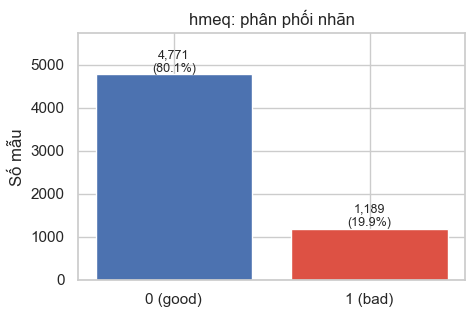

In [4]:
tgt = eda.target_summary(df["target"])
print(tgt)
eda.plot_target(df["target"], NAME)

## 4. Giá trị thiếu

Bảng thứ hai so sánh tỉ lệ nợ xấu khi cột bị thiếu và khi có giá trị: chênh lệch lớn nghĩa là *bản thân việc thiếu* đã mang thông tin về nhãn.

In [5]:
miss = eda.missing_table(df)
display(miss if len(miss) else "Không có giá trị thiếu (NaN).")
mvt = eda.missing_vs_target(df)
display(mvt if len(mvt) else "Không có cột nào đủ lượng thiếu để so sánh bad rate.")

,missing_pct
DEBTINC,21.26
DEROG,11.88
DELINQ,9.73
MORTDUE,8.69
YOJ,8.64
NINQ,8.56
CLAGE,5.17
JOB,4.68
REASON,4.23
CLNO,3.72


,feature,missing_pct,bad_rate_if_missing,bad_rate_if_present,gap
0,VALUE,1.88,93.75,18.54,75.21
1,DEBTINC,21.26,62.04,8.59,53.45
2,JOB,4.68,8.24,20.52,-12.28
3,DEROG,11.88,12.29,20.98,-8.69
4,DELINQ,9.73,12.41,20.76,-8.35
5,YOJ,8.64,12.62,20.64,-8.02
6,NINQ,8.56,14.71,20.44,-5.73
7,CLAGE,5.17,25.32,19.66,5.66
8,CLNO,3.72,23.87,19.80,4.07
9,REASON,4.23,19.05,19.99,-0.94


## 5. Hồ sơ các biến số

`skew`/`kurtosis`: độ lệch và độ nhọn; `outlier_iqr_pct`: % điểm nằm ngoài 1.5×IQR; `zero_pct`: % giá trị 0; `auc`: AUC đơn biến (max(AUC, 1−AUC)) — thước đo nhanh sức phân biệt của từng biến.

In [6]:
prof = eda.numeric_profile(df)
cols_show = ["n_unique", "min", "median", "max", "skew", "kurtosis", "outlier_iqr_pct", "zero_pct", "auc"]
display(prof.sort_values("auc", ascending=False)[cols_show])
print("Số cột số có |skew| > 2:", int((prof["skew"].abs() > 2).sum()), "/", len(prof))

,n_unique,min,median,max,skew,kurtosis,outlier_iqr_pct,zero_pct,auc
feature,,,,,,,,,
DELINQ,14,0.000,0.000,15.000,4.022,23.542,NaN,77.677,0.672
DEBTINC,4693,0.524,34.818,203.312,2.851,50.449,2.003,0.000,0.651
CLAGE,5314,0.000,173.467,1168.234,1.343,7.592,0.832,0.035,0.635
DEROG,11,0.000,0.000,10.000,5.319,36.837,NaN,86.196,0.616
NINQ,16,0.000,1.000,17.000,2.621,9.776,3.248,46.440,0.602
LOAN,540,1100.000,16300.000,89900.000,2.023,6.926,4.295,0.000,0.578
VALUE,5381,8000.000,89235.500,855909.000,3.053,24.341,5.472,0.000,0.557
MORTDUE,5053,2063.000,65019.000,399550.000,1.814,6.475,4.300,0.000,0.555
YOJ,99,0.000,7.000,41.000,0.988,0.371,1.671,7.622,0.540


Số cột số có |skew| > 2: 6 / 10


## 6. Phân phối theo nhãn

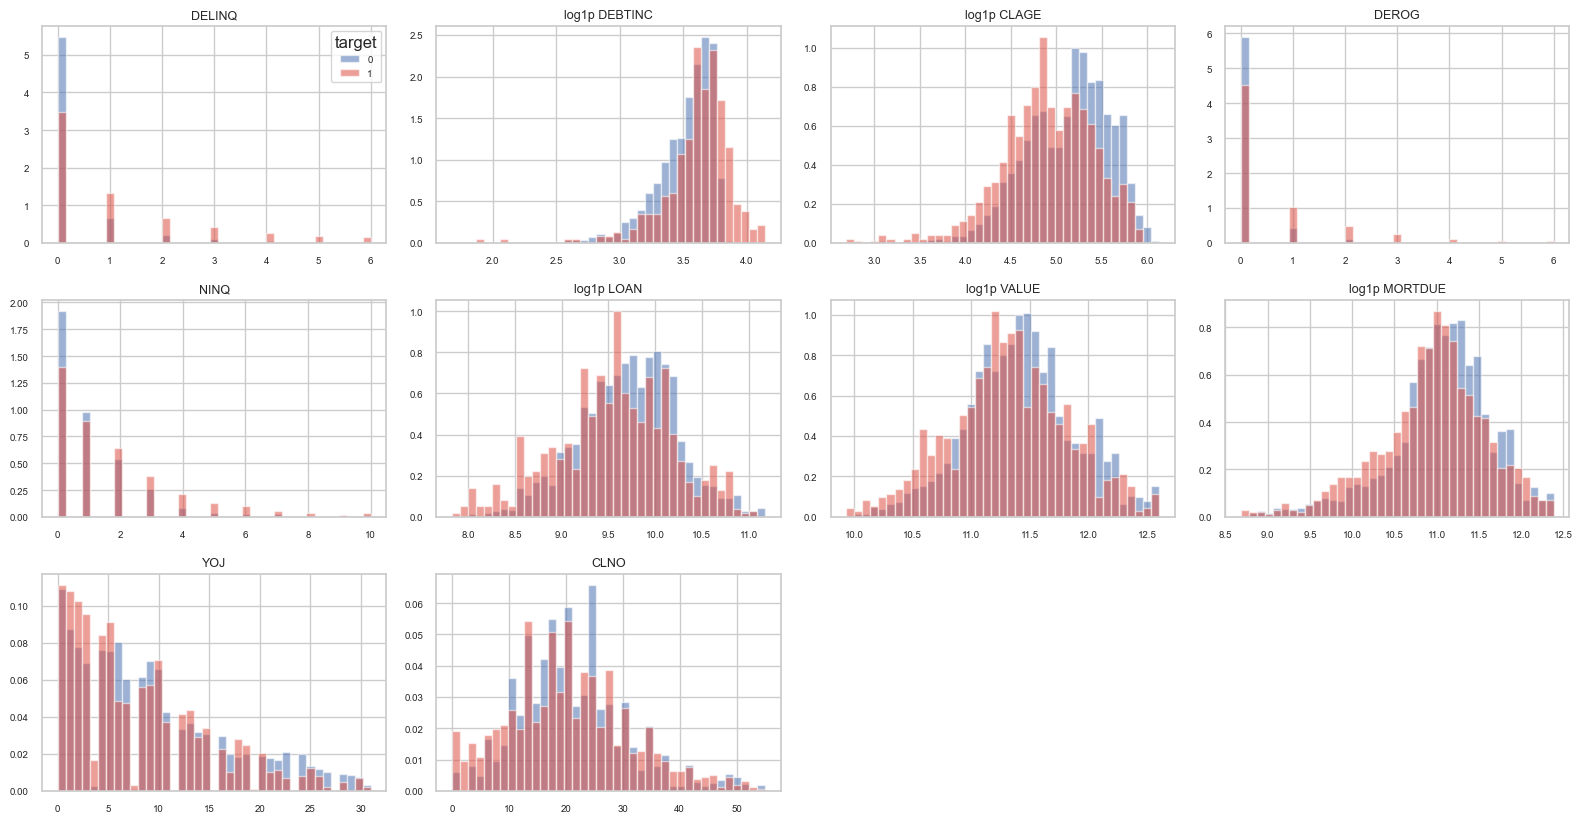

In [7]:
top = prof.sort_values("auc", ascending=False).index[:10].tolist()
eda.plot_numeric_by_target(df, top, NAME, log=["LOAN", "MORTDUE", "VALUE", "DEBTINC", "CLAGE"])

## 7. Biến phân loại: tỉ lệ nợ xấu theo nhóm

Đường nét đứt = bad rate chung.

n  bad_rate  share_pct
feature level                             
REASON  <NA>      252     19.05       4.23
        DebtCon  3928     18.97      65.91
        HomeImp  1780     22.25      29.87
JOB     <NA>      279      8.24       4.68
        Mgr       767     23.34      12.87
        Office    948     13.19      15.91
        Other    2388     23.20      40.07
        ProfExe  1276     16.61      21.41
        Sales     109     34.86       1.83
        Self      193     30.05       3.24

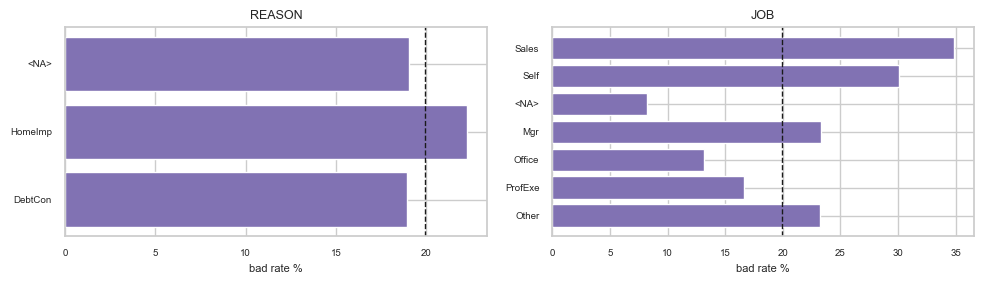

In [8]:
cats = ["REASON", "JOB"]
display(eda.categorical_bad_rate(df, cats))
eda.plot_categorical_bad_rate(df, cats, NAME, ncols=2)

## 8. Tương quan

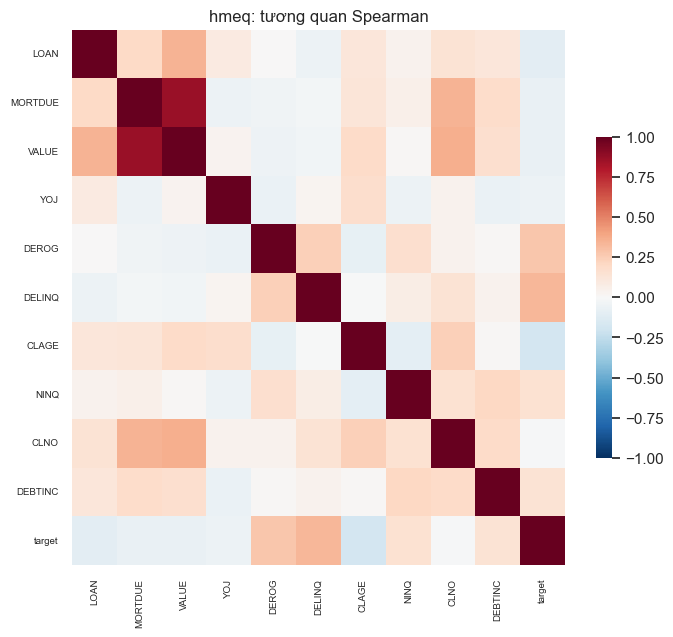

,a,b,spearman


In [9]:
corr = eda.correlation_heatmap(df, NAME)
display(eda.high_corr_pairs(corr, thr=0.9).head(20))

## 9. Kiểm tra riêng cho bộ dữ liệu

### Số dòng bị thiếu nhiều cột cùng lúc

In [10]:
n_miss = df.drop(columns="target").isna().sum(axis=1)
display(df.groupby(n_miss.clip(upper=6))["target"].agg(["size", "mean"]).rename(
    columns={"size": "n", "mean": "bad_rate"}).rename_axis("số cột thiếu (≥6 gộp)"))

,n,bad_rate
số cột thiếu (≥6 gộp),,
0,3364,0.089180
1,1589,0.381372
2,449,0.400891
3,219,0.178082
4,64,0.093750
5,83,0.096386
6,192,0.260417


In [11]:
# DEROG/DELINQ gần như là biến đếm rời rạc với phần lớn = 0
for c in ["DEROG", "DELINQ", "NINQ"]:
    display(df.groupby(df[c].clip(upper=5))["target"].agg(["size", "mean"]).rename_axis(f"{c} (≥5 gộp)").T)

DEROG (≥5 gộp),0.0,1.0,2.0,3.0,4.0,5.0
size,4527.000000,435.000000,160.0000,58.000000,23.000000,49.000000
mean,0.166556,0.388506,0.5125,0.741379,0.782609,0.734694


DELINQ (≥5 gộp),0.0,1.0,2.0,3.0,4.0,5.0
size,4179.000000,654.00000,250.000,129.000000,78.000000,90.000000
mean,0.139507,0.33945,0.448,0.550388,0.589744,0.922222


NINQ (≥5 gộp),0.0,1.0,2.0,3.0,4.0,5.0
size,2531.00000,1339.000000,780.000000,392.000000,156.000000,252.000000
mean,0.15646,0.189694,0.232051,0.272959,0.391026,0.456349


## 10. Nhận xét

- **Nhãn:** bad rate ≈ **20%** (1.189/5.960), mất cân bằng ở mức vừa (≈ 4:1). Không cần xử lý đặc biệt ngoài việc dùng stratified split và các metric không phụ thuộc ngưỡng (AUC, PR-AUC).
- **Thiếu dữ liệu có tính thông tin rất mạnh (bất thường):** khi thiếu giá trị tài sản (`VALUE`) thì bad rate ≈ **94%**; khi thiếu tỉ lệ nợ/thu nhập (`DEBTINC`, thiếu ~21%) bad rate ≈ **62%** so với ~9% khi có giá trị. Điều này gợi ý việc thiếu gắn liền với quy trình xét duyệt/thu hồi nợ — một dạng *rò rỉ thông tin* (leakage) tiềm tàng. Mô hình cây sẽ khai thác rất mạnh đặc điểm này; cần cân nhắc khi diễn giải kết quả.
- Ngược lại, thiếu `DEROG`, `DELINQ`, `YOJ`, `JOB` lại đi kèm bad rate *thấp hơn* trung bình.
- **Độ lệch:** các biến tiền tệ (`LOAN`, `MORTDUE`, `VALUE`) lệch phải (skew 2–3); `DEBTINC` có đuôi rất dài (kurtosis ≈ 50, max > 200%). Các biến đếm (`DEROG`, `DELINQ`) tập trung ở 0 (78–86% bằng 0) nhưng là các biến phân biệt tốt nhất.
- Không có dòng trùng lặp. Kích thước nhỏ → phương sai đánh giá cao, nên dùng cross-validation.

In [12]:
EXTRA = {"informative_missing": mvt.head(3).to_dict("records")}
eda.save_summary(NAME, {
    "name": NAME,
    "overview": ov.to_dict(),
    "target": tgt,
    "missing_top": miss["missing_pct"].head(10).to_dict() if len(miss) else {},
    "n_numeric_abs_skew_gt2": int((prof["skew"].abs() > 2).sum()),
    "n_numeric": int(len(prof)),
    "max_abs_skew": float(prof["skew"].abs().max()),
    "top_auc": prof["auc"].sort_values(ascending=False).head(5).to_dict(),
    **EXTRA,
})